# ACCESS-OM3 MC 100km JRA RYF: CICE6 cores and block sizes

How the number of cores given to CICE6, and the size of the blocks it divides its grid into, change the performance of the [ACCESS-OM3 MC 100km JRA RYF configuration](https://github.com/ACCESS-NRI/access-om3-configs/tree/dev-MC_100km_jra_ryf). The [scaling study](https://github.com/ACCESS-NRI/access-model-scaling/blob/main/ACCESS-OM3/dev-MC_100km_jra_ryf.ipynb) of this configuration found CICE6 to be its scaling bottleneck. Here every other component keeps the cores of the control: 288 for MOM6, and 24 each for the mediator, the data atmosphere and the data runoff.

In [1]:
%load_ext autoreload
%autoreload 2

# Record package versions for future reference
from importlib.metadata import version
for pkg in ("access.config.utils", "access.profiling", "payu", "experiment_generator", "experiment_runner"):
    print(f"{pkg}: {version(pkg)}")

access.config.utils: 0.6.dev10+gca45c2cf0
access.profiling: 0.3.dev84+g4f1c96f19
payu: 1.3.6
experiment_generator: 0.10.2
experiment_runner: 0.3.2


In [2]:
## Imports
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from access.config.parallel_allocation_strategies import FixedAllocation, FreeAllocation, RootAllocation
from ruamel.yaml.scalarstring import DoubleQuotedScalarString as dq

from access.profiling import (
    ConfigurationChoice,
    GitControlSource,
    PayuManager,
    ProfilingExperimentStatus,
    RegionGroup,
)
from access.profiling.manager import component_cores, find_component
from access.profiling.metrics import tmax
from access.profiling.models.om3 import OM3_MC_100KM, OM3_MC_100KM_CORES

## Setup
The following variables control where the configurations and model run outputs are saved.

In [3]:
work_path = "/g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/work"
archive_path = "/g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive"
lab_path = "/scratch/tm70/mo1833/profiling/lab"

# The spin-up: one cold-start run of the control, whose restart files every experiment starts from
spinup_work_path = "/g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/spinup/work"
spinup_archive_path = "/g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/spinup/archive"

# The same control as the scaling study of this configuration (dev-MC_100km_jra_ryf.ipynb), so that the two compare
OM3_MC_100KM_SOURCE: GitControlSource = GitControlSource(
    repository="https://github.com/ACCESS-NRI/access-om3-configs.git",
    start_point="7d4166c9e812306edf10a9bfe843739916c3e0e1",
)

# Create profiling manager. It holds every experiment of the study, whatever its block size.
om3_profiling = PayuManager(work_dir=Path(work_path), archive_dir=Path(archive_path), application=OM3_MC_100KM, control=OM3_MC_100KM_SOURCE, lab_dir=Path(lab_path))

## Spin-up

The model starts without sea ice, so its first year is not like the ones that follow: CICE6 has less work to do in it. We therefore run the control once, for one year, from a cold start. This run is not timed. Every run of every experiment then starts from the restart files it writes, so that all the runs simulate the same year from the same state.

The spin-up is generated with a manager of its own, so that it is not parsed or plotted with the experiments. It uses the same control options as the experiments, which turn on the ESMF profiling summary and remove what the control only needs for production runs.

In [4]:
# The control options of the spin-up, which the experiments add the repeats to
control_options = {
    "config.yaml": {
        "umask": 0o2,
        "manifest": {"reproduce": {"exe": False}},
        "postscript": "REMOVE",
        "mem": "REMOVE",
        "env": {"ESMF_RUNTIME_PROFILE": dq("on"), "ESMF_RUNTIME_PROFILE_OUTPUT": dq("SUMMARY")},
    }
}

# The control as it is, with the 24 CICE6 cores and the 15x20 blocks of its release, run once
spinup = PayuManager(
    work_dir=Path(spinup_work_path),
    archive_dir=Path(spinup_archive_path),
    application=OM3_MC_100KM,
    control=OM3_MC_100KM_SOURCE,
    lab_dir=Path(lab_path),
)
spinup.generate_experiments([ConfigurationChoice()], control_options=control_options)
spinup.run_experiments()

No new experiments to generate. Will skip generation.


The experiments can only be generated once the spin-up has finished, since they are told where its restart files are. The next cell stops with an error until then. Archive the spin-up only after the experiments have run, since every run reads its restart files. The restart files are not archived, so once the spin-up has been archived, no experiment is generated: they are all found again in the archives.

In [5]:
# The restart files of the spin-up, which it has only once it has finished. They are not archived, so an archived
# spin-up has none: by then, every experiment has been generated, and is found again in the archives.
spinup.update_statuses()
(spinup_run,) = spinup.experiments.values()
if spinup_run.status == ProfilingExperimentStatus.ARCHIVED:
    spinup_restart = None
elif spinup_run.status == ProfilingExperimentStatus.DONE:
    spinup_restart = (spinup_run.path / "archive" / "restart000").resolve(strict=True)
else:
    raise RuntimeError(f"The spin-up is {spinup_run.status.name}. Wait for it to finish before going on.")
spinup_restart

## Block sizes

CICE6 divides its 360x324 grid into blocks, and hands the blocks out to its ranks. The control distributes them `cartesian`, with the processor shape `slenderX1`. This means that each rank gets a rectangle of neighbouring blocks, and that the ranks are arranged in a single row whenever the blocks allow it. The configuration provided by access-profiling as `OM3_MC_100KM` keeps that distribution, and chooses the block size from the number of ranks, so that each rank holds 5 to 8 blocks.

We vary how many blocks each rank holds, which sets how large the blocks are: one block per rank, 2 to 4, 5 to 8 (as in `OM3_MC_100KM`), 9 to 16, and 17. The last one is how the control runs: its 15x20 blocks give each of its 24 ranks 17 blocks. Each experiment states its block size as a change to `ice_in`, and is labelled with its blocks per rank.

In [6]:
# How many blocks each CICE6 rank holds, both bounds included, keyed by the label given to the experiments
blocks_per_rank_ranges = {
    "1": (1, 1),
    "2-4": (2, 4),
    "5-8": (5, 8),
    "9-16": (9, 16),
    "17": (17, 17),
}

## Generate experiments

MOM6 keeps the 288 cores of the control, and the mediator, the data atmosphere and the data runoff keep their 24 cores. CICE6 gets at least 8 cores, in steps of 4. CICE6 takes turns with the mediator and the data components on the same cores, so giving it more than 24 cores makes the job larger.

We use 3 and 4 Sapphire Rapids nodes. On 3 nodes, CICE6 gets 8 to 24 cores, and no core is left idle. On 4 nodes, it gets 28 to 128 cores, and the cores it does not use are left idle. A layout that fits on 3 nodes is only kept once, on 3 nodes. The strategy sets no limit on the number of idle cores, so that the other components keep their cores whatever CICE6 gets.

Not every number of cores can be used: the blocks have to be shared out evenly among the ranks. The layout search only finds the numbers of CICE6 cores for which `OM3_MC_100KM` has a block size.

In [7]:
num_nodes_list = [3.0, 4.0]
cores_per_node = 104

# Define how the cores should be allocated to the components:
#   - MOM6, the mediator, the data atmosphere and the data runoff keep the cores of the control.
#   - CICE6 gets at least 8 cores, in multiples of 4. Which of these it can run on depends on its block size.
#   - No limit is set on the number of idle cores.
allocations = RootAllocation(
    subcomponents={
        "ocn": FixedAllocation(OM3_MC_100KM_CORES["ocn"]),
        "shared": FreeAllocation(
            subcomponents={
                "cpl": FixedAllocation(OM3_MC_100KM_CORES["cpl"]),
                "atm": FixedAllocation(OM3_MC_100KM_CORES["atm"]),
                "rof": FixedAllocation(OM3_MC_100KM_CORES["rof"]),
                "ice": FreeAllocation(min_cores=8, core_step=4),
            },
        ),
    },
)

# Search for the layouts of each number of nodes. A layout found on 3 nodes is found again on 4 nodes, with more idle
# cores, so only the first one found is kept.
layouts = {}
for num_nodes in num_nodes_list:
    for layout in om3_profiling.select_layouts(int(num_nodes * cores_per_node), allocations=allocations):
        layouts.setdefault(om3_profiling.application.layout_key(layout), layout)
layouts = sorted(layouts.values(), key=lambda layout: find_component(layout, "ice").n_cores)
print(f"Number of layouts: {len(layouts)}")

Number of layouts: 13


Each experiment is a configuration choice: a layout, and the changes it makes to the control. The changes are the block size of one of the ranges of blocks per rank, and the walltime. `block_size_choices` makes one choice for each range and each layout, and leaves out a range that has no block size for a number of CICE6 cores.

The table below gives the block size of each experiment and, in brackets, the grid of ranks CICE6 arranges them in, along x and along y. The processor shape `slenderX1` puts the ranks in a single row, as in `24x1`, but CICE6 keeps to it only as far as the blocks allow. A grid such as `1x36` means that CICE6 stacked the ranks in a column instead. Each rank then holds a band of latitudes, some of which may be all land, so the experiment changes how the ranks are arranged as well as the block size.

In [8]:
# The control asks for 2 hours with 24 CICE6 cores, and CICE6 on 8 cores can take about three times as long
walltime = {"config.yaml": {"walltime": "6:00:00"}}

# One configuration choice for each range of blocks per rank and for each layout. The experiments are numbered in this
# order, which is also the order of the lines and of the bars in the plots.
choices = om3_profiling.application.block_size_choices(layouts, blocks_per_rank_ranges, changes=walltime)
print(f"Number of experiments: {len(choices)}")

# The block size of each experiment, and the grid of ranks CICE6 arranges them in
block_sizes = {}
for label, blocks_per_rank in blocks_per_rank_ranges.items():
    partitioning = replace(om3_profiling.application.sea_ice, blocks_per_rank_range=blocks_per_rank)
    block_sizes[label] = {}
    for layout in layouts:
        ice_cores = find_component(layout, "ice").n_cores
        blocks = partitioning.blocks(ice_cores)
        if blocks is not None:
            (block_x, block_y), (ranks_x, ranks_y) = blocks.block_shape, blocks.process_grid
            block_sizes[label][ice_cores] = f"{block_x}x{block_y} ({ranks_x}x{ranks_y})"
pd.DataFrame(block_sizes).sort_index().rename_axis("CICE6 cores")

Number of experiments: 65


,1,2-4,5-8,9-16,17
CICE6 cores,,,,,
8,45x324 (8x1),45x81 (8x1),45x54 (8x1),45x36 (8x1),45x20 (8x1)
12,30x324 (12x1),30x81 (12x1),45x27 (1x12),30x27 (12x1),22x27 (1x12)
16,23x324 (16x1),23x81 (16x1),23x54 (16x1),23x27 (16x1),23x20 (16x1)
20,18x324 (20x1),18x81 (20x1),18x54 (20x1),18x27 (20x1),18x20 (20x1)
24,15x324 (24x1),15x81 (24x1),15x54 (24x1),15x27 (24x1),15x20 (24x1)
28,13x324 (28x1),13x81 (28x1),13x54 (28x1),13x27 (28x1),13x20 (28x1)
36,10x324 (36x1),10x81 (36x1),45x9 (1x36),24x9 (1x36),22x9 (1x36)
40,9x324 (40x1),9x81 (40x1),9x54 (40x1),9x27 (40x1),9x20 (40x1)
52,7x324 (52x1),7x81 (52x1),7x54 (52x1),7x27 (52x1),7x20 (52x1)


In [9]:
###### Generate the configurations and write to file
# Every run of every experiment repeats the same year, from the restart files of the spin-up. Without them, the
# spin-up has been archived, and every experiment has been generated before it.
if spinup_restart is None:
    print("The spin-up is archived without its restart files, so no experiment is generated.")
else:
    study_options = {"config.yaml": {**control_options["config.yaml"], "repeat": True, "restart": str(spinup_restart)}}
    om3_profiling.generate_experiments(choices, control_options=study_options)

The spin-up is archived without its restart files, so no experiment is generated.


## Run experiments

Each experiment runs 3 times, so that we can tell how much its times vary from run to run. With Payu's `repeat` option, every run starts from the restart files of the spin-up, so the 3 runs are the same simulation of the same year, and only the noise differs between them. Each run is a job of its own, so the walltime set above is that of one run.

In [10]:
# Run every experiment 3 times, each run a repeat of the same year
om3_profiling.nruns = 3
om3_profiling.run_experiments()

## Parsing and plotting experiment results

In [11]:
# Parse the data. The runs of each experiment are along a 'run' dimension.
om3_profiling.parse_profiling_data()

The experiments are numbered, so their names do not say which is which. Two things tell them apart: the number of CICE6 cores, which is read from the layout of each experiment, and the blocks per rank, which is their label. We use both to tabulate the maximum time of a region over the PETs, the processes of ESMF, with a row for each number of CICE6 cores and a column for each number of blocks per rank. An experiment with a failed run is not parsed, so it is missing from the tables and the plots.

In [12]:
# What tells the experiments apart: the cores of CICE6, from their layouts, and their label
coordinates = [component_cores("ice"), "blocks per rank"]

whole_model = RegionGroup("ESMF", ["[ensemble] RunPhase1"], relabel={"[ensemble] RunPhase1": "Full model"})
ocean = RegionGroup("ESMF", ["[OCN] RunPhase1"], relabel={"[OCN] RunPhase1": "MOM6"})
cice6 = RegionGroup("ESMF", ["[ICE] RunPhase1"], component="ice", relabel={"[ICE] RunPhase1": "CICE6"})

The 3 runs of an experiment are the same simulation, so the differences between their times are noise. The table below gives, for each experiment, how far apart its slowest and its fastest run are, in percent of the fastest, for CICE6, the whole model and MOM6. A difference between two experiments that is smaller than the spread cannot be told apart from noise.

In [13]:
# How far apart the slowest and the fastest run of each experiment are, in percent of the fastest
def run_spread(group):
    fastest = om3_profiling.table(group, tmax, *coordinates, runs="min")
    slowest = om3_profiling.table(group, tmax, *coordinates, runs="max")
    return 100 * (slowest - fastest) / fastest


pd.concat([run_spread(cice6), run_spread(whole_model), run_spread(ocean)], axis=1).round(1)

region          CICE6                       Full model                      \
blocks per rank     1  2-4  5-8  9-16    17          1  2-4  5-8 9-16   17   
ice cores                                                                    
8                 1.1  0.5  2.3   1.1   1.5        0.7  0.9  1.0  0.8  1.2   
12                0.3  1.7  3.1   0.9   0.6        0.7  1.1  2.7  1.0  0.6   
16                0.4  1.2  3.6   0.7   0.9        0.4  0.8  2.4  0.2  5.4   
20                1.6  0.8  2.1   2.1   0.6        1.3  0.7  1.0  0.7  0.4   
24                2.9  1.5  4.7   2.1   3.0        2.0  1.3  1.4  0.5  1.3   
28                1.2  1.4  0.4   2.8   2.2        1.6  1.4  0.5  1.2  0.6   
36                2.0  1.5  1.5   2.7   1.3        1.1  0.6  1.5  1.2  1.8   
40                1.8  3.8  0.7   3.0   4.9        1.1  1.4  1.1  1.0  2.4   
52                4.5  4.5  3.7   2.6   3.8        1.9  1.8  1.6  1.2  1.3   
60                3.0  4.6  4.5   1.7   0.8        1.6  2.1  1.6  2.4  1.3   
72                7.3  7.5  4.3   7.1  10.8        2.4  2.2  1.0  3.3  1.9   
108               2.7  8.1  3.2   9.3   3.7        1.6  1.9  2.0  2.2  0.9   
120               2.5  8.4  6.1  10.8  13.7        4.3  2.0  1.6  2.6  1.6   

region          MOM6                       
blocks per rank    1  2-4  5-8 9-16    17  
ice cores                                  
8                0.9  0.6  0.4  0.2   1.2  
12               1.6  1.3  3.0  0.7   0.5  
16               0.6  0.7  1.6  1.0  15.7  
20               1.0  0.7  0.3  0.9   0.4  
24               0.9  0.9  1.4  0.4   0.2  
28               1.1  0.8  0.2  0.8   0.5  
36               0.4  0.7  0.8  0.8   2.8  
40               0.8  0.9  0.5  0.7   1.9  
52               1.4  1.1  1.1  1.5   0.8  
60               1.3  1.2  1.9  2.2   1.3  
72               2.0  1.0  0.6  2.1   0.1  
108              1.0  1.0  1.6  0.2   0.8  
120              4.5  1.3  1.6  1.1   0.9

From here on, each experiment is represented by the run in which CICE6 was the fastest. That run is kept whole, so that the times of CICE6, of MOM6 and of the whole model in the tables and the plots all come from it. This cannot be undone: parse the data again to get every run back.

In [14]:
# Keep, for each experiment, the run in which CICE6 was the fastest. The run is kept whole, in every log.
om3_profiling.select_best_run("ESMF", "[ICE] RunPhase1", tmax)

cice_times = om3_profiling.table(cice6, tmax, *coordinates)
model_times = om3_profiling.table(whole_model, tmax, *coordinates)
ocean_times = om3_profiling.table(ocean, tmax, *coordinates)

# Time-stepping of CICE6, in seconds
cice_times

region               CICE6                                            
blocks per rank          1        2-4        5-8       9-16         17
ice cores                                                             
8                2405.2500  2383.4866  2126.7537  2262.3176  2304.5596
12               1878.0663  1791.4498  2162.8938  1743.8130  2133.8452
16               1568.0426  1531.3754  1391.6389  1482.0364  1499.7947
20               1147.9418  1141.2783  1085.6721  1104.5745  1074.1006
24               1032.8312  1004.3986   918.5535   943.2789   943.0856
28                975.2855   949.7533   868.0316   885.6713   887.2828
36                717.6825   737.0327  1030.4043  1022.8314  1007.8872
40                708.9666   665.9984   630.4840   622.6707   624.1163
52                620.7946   603.5345   561.6821   568.7904   578.2097
60                523.6525   500.6283   495.9089   487.2861   509.2426
72                478.5919   451.5050   446.6050   450.9736   462.4285
108               491.5066   459.9862   461.0463   470.3249   467.8523
120               374.5134   350.8676   332.4428   344.0201   356.6107

In [15]:
# Time-stepping of the whole model, in seconds
model_times

region          Full model                                            
blocks per rank          1        2-4        5-8       9-16         17
ice cores                                                             
8                3005.0439  3004.2131  2857.4985  2930.7051  2951.7627
12               2723.2158  2647.2722  2871.6467  2624.0747  2855.4512
16               2533.0166  2504.8284  2418.8567  2483.8870  2625.8992
20               2268.5718  2279.2859  2235.4060  2261.6748  2234.7092
24               2211.6643  2190.3977  2145.5667  2163.9724  2152.8916
28               2203.6929  2201.0176  2165.6162  2181.8081  2194.6145
36               2154.3022  2177.8289  2231.1890  2223.5649  2260.1035
40               2183.3994  2184.9099  2182.8789  2177.7900  2157.1653
52               2142.8665  2129.5911  2151.8928  2168.7874  2139.0046
60               2148.4661  2159.8586  2150.8916  2134.1895  2164.8428
72               2115.2104  2089.5667  2104.8477  2093.6335  2115.8540
108              2141.2605  2106.5762  2095.2717  2098.4207  2102.8630
120              2141.5552  2110.9355  2117.9275  2101.8015  2111.8882

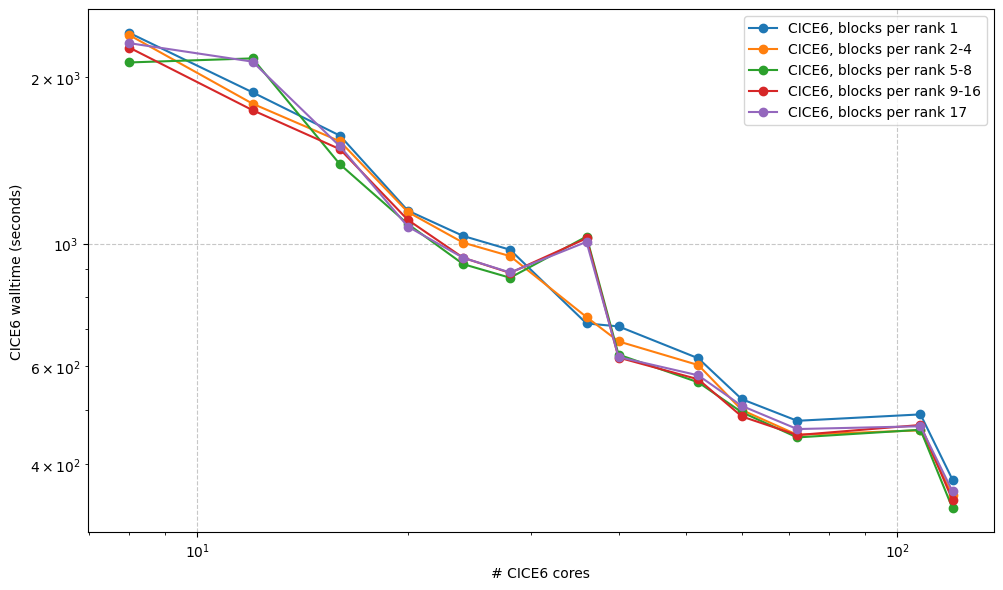

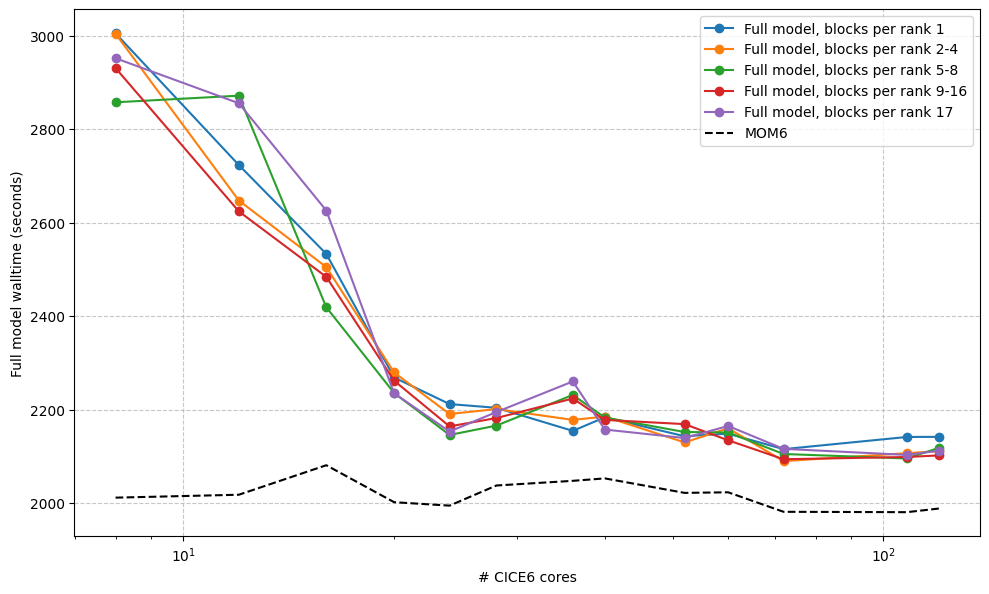

In [16]:
# Plot the time-stepping of CICE6 against its number of cores, with a line for each number of blocks per rank
fig = om3_profiling.plot_metric(
    [cice6],
    tmax,
    component_cores("ice"),
    series="blocks per rank",
    xlabel="# CICE6 cores",
    ylabel="CICE6 walltime (seconds)",
    show=False,
)
fig.axes[0].set(xscale="log", yscale="log")
plt.show()

# Plot the time-stepping of the whole model in the same way. The dashed line is the time-stepping of MOM6, which the
# whole model cannot run faster than.
fig = om3_profiling.plot_metric(
    [whole_model],
    tmax,
    component_cores("ice"),
    series="blocks per rank",
    xlabel="# CICE6 cores",
    ylabel="Full model walltime (seconds)",
    show=False,
)
fig.axes[0].plot(ocean_times.index, ocean_times.mean(axis=1), "k--", label="MOM6")
fig.axes[0].set(xscale="log")
fig.axes[0].legend()
plt.show()

CICE6 writes its own timers at the end of its log, which show where its time goes. We compare the block sizes on 24 cores, the number of cores of the control. `Dynamics` is the sea ice dynamics, `Advection` the transport of the sea ice, and `Column` the thermodynamics and the other processes of each column. `Bound` is the time spent updating the halos of the blocks, part of which is also counted in `Dynamics` and `Advection`.

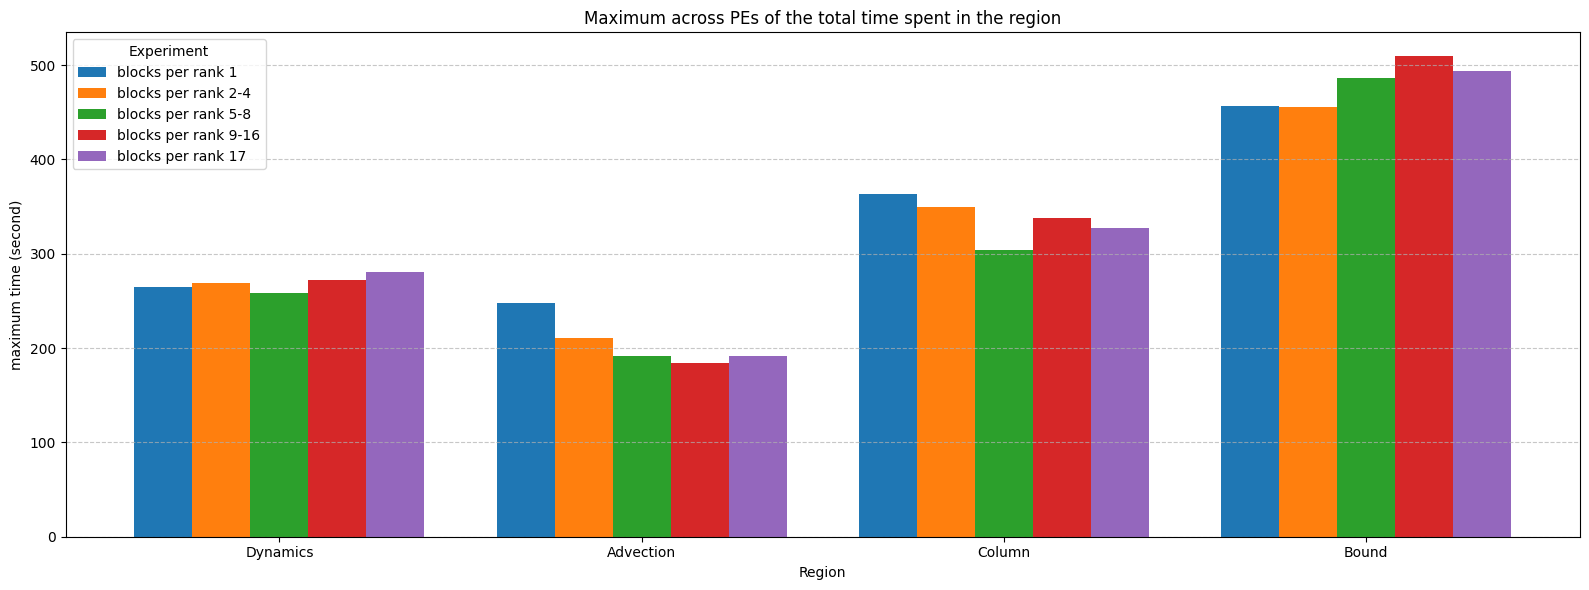

In [17]:
# Plot CICE6's own timers on the 24 cores of the control, with a bar for each number of blocks per rank
cice_regions = ["Dynamics", "Advection", "Column", "Bound"]
cice_timers = RegionGroup("CICE6", cice_regions, relabel={region: region for region in cice_regions})

on_control_cores = om3_profiling.select_experiments(component_cores("ice"), OM3_MC_100KM_CORES["ice"])
fig = om3_profiling.plot_bar_chart([cice_timers], tmax, experiments=on_control_cores, label="blocks per rank")

Finally, for each number of blocks per rank, we plot how the time-stepping of CICE6 and its own timers change with its number of cores. The black lines show ideal scaling.

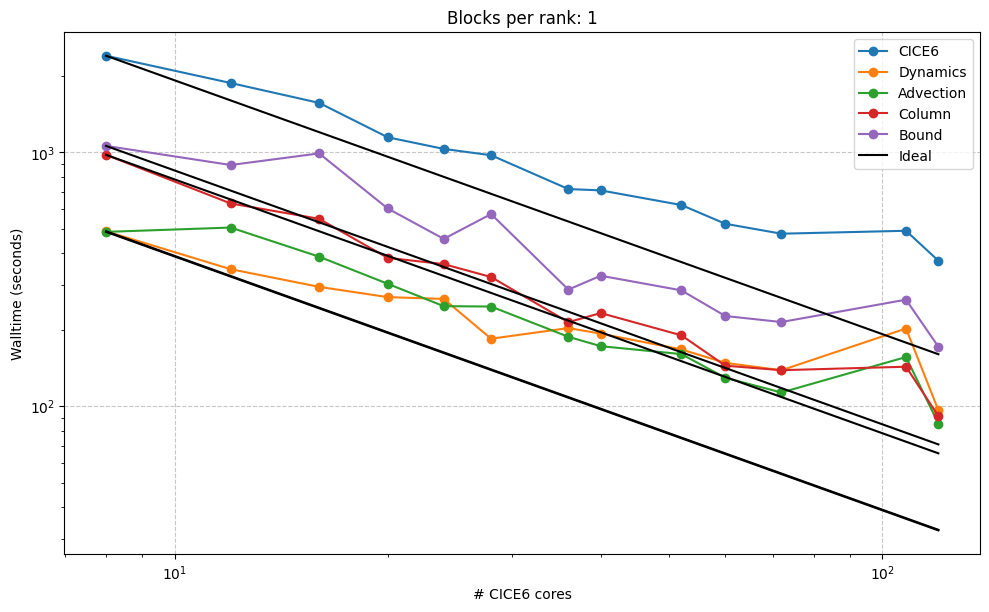

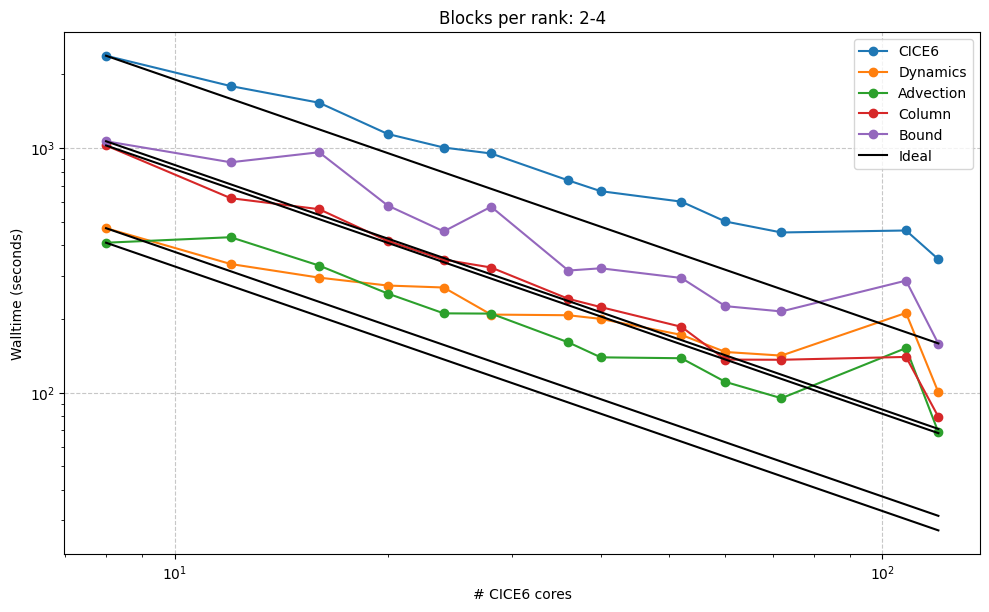

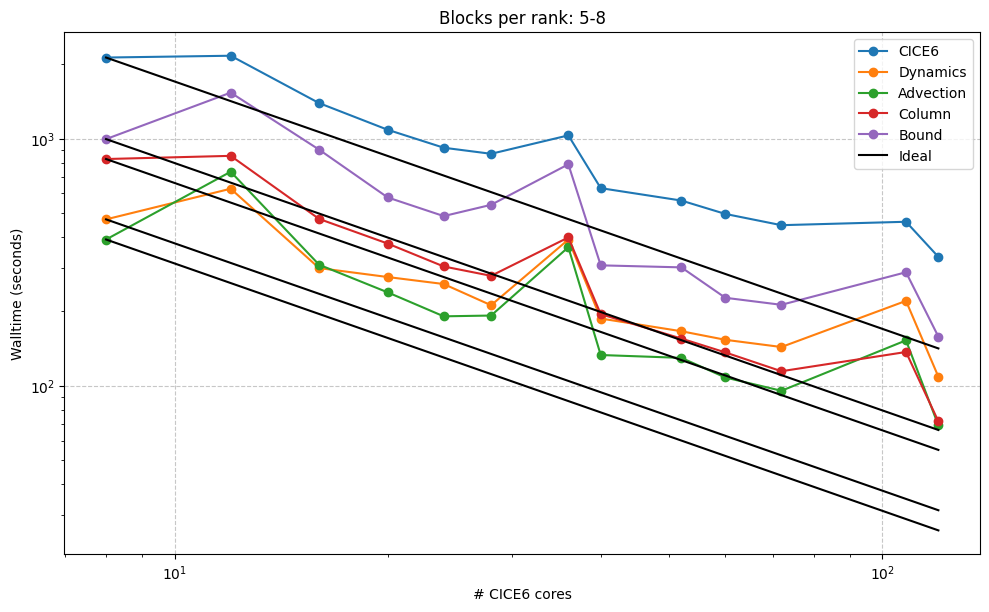

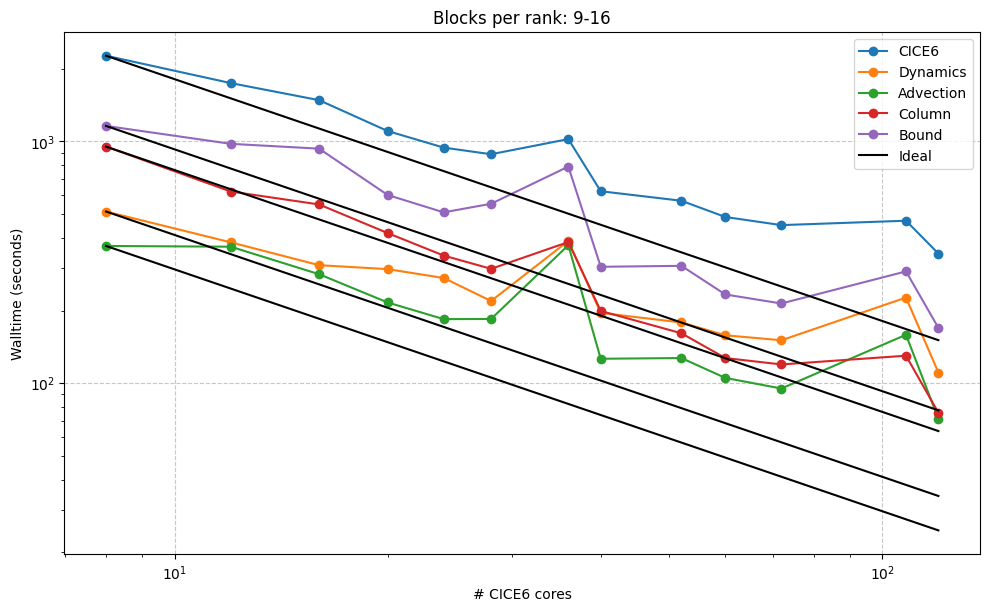

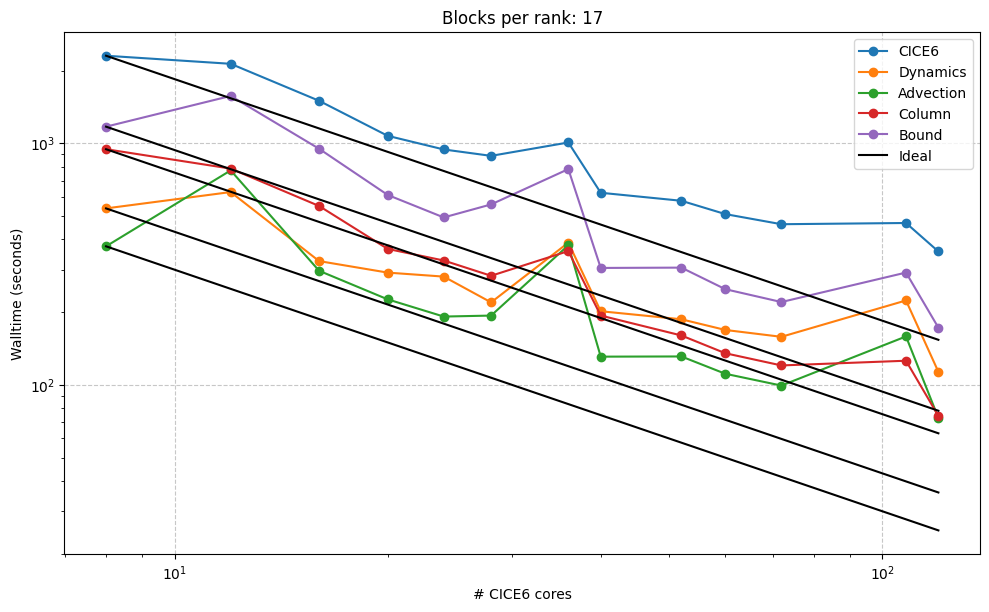

In [18]:
for label in blocks_per_rank_ranges:
    labelled = om3_profiling.select_experiments("blocks per rank", label)
    if not labelled:
        continue  # None of these experiments has been parsed
    fig = om3_profiling.plot_component_scaling_data(
        [cice6, cice_timers],
        metric=tmax,
        experiments=labelled,
        xlabel="# CICE6 cores",
        ylabel="Walltime (seconds)",
        show=False,
    )
    fig.axes[0].set_title(f"Blocks per rank: {label}")
    plt.show()

## Sea ice

The work of CICE6 depends on how much sea ice there is. The runs simulate the second year after a start without sea ice, while a production run starts from a state that has been spun up over many years. The runs may therefore have less sea ice than a production run, which would make CICE6 faster in them.

To check this, we computed the sea ice extent, the area of the cells with an ice concentration above 15%, from the daily output of CICE6 in the control experiment (24 CICE6 cores with 17 blocks per rank) and in the spin-up. The sea ice is the same in every run of every experiment. We compared it with the daily 1981-2010 climatology of the [NSIDC Sea Ice Index, version 4](https://nsidc.org/data/g02135/versions/4), which covers the period of the 1990/91 forcing. The daily output of CICE6 is not archived, so this comparison cannot be repeated from the archives, and only its results are given here. The monthly means of the extent, in million km², were:

| | Arctic, observed | Arctic, runs | Arctic, spin-up | Antarctic, observed | Antarctic, runs | Antarctic, spin-up |
|---|---|---|---|---|---|---|
| January | 14.4 | 13.2 | 12.7 | 5.0 | 4.3 | 0.0 |
| February | 15.3 | 13.9 | 13.8 | 3.1 | 1.5 | 0.0 |
| March | 15.4 | 14.0 | 13.8 | 4.0 | 1.6 | 0.6 |
| April | 14.7 | 13.6 | 13.6 | 6.8 | 5.8 | 4.1 |
| May | 13.3 | 12.3 | 12.3 | 10.1 | 9.5 | 8.3 |
| June | 11.8 | 10.8 | 10.5 | 13.3 | 12.7 | 12.0 |
| July | 9.5 | 8.7 | 7.9 | 15.9 | 15.1 | 14.8 |
| August | 7.2 | 6.1 | 4.6 | 17.7 | 16.8 | 16.8 |
| September | 6.4 | 5.4 | 3.8 | 18.5 | 17.3 | 17.3 |
| October | 8.3 | 7.5 | 7.2 | 18.1 | 16.9 | 16.9 |
| November | 10.7 | 10.2 | 10.1 | 15.9 | 15.4 | 15.3 |
| December | 12.8 | 12.1 | 12.1 | 10.5 | 11.8 | 11.4 |
| Year | 11.6 | 10.6 | 10.2 | 11.6 | 10.8 | 9.8 |

Over the year, the runs have 8% less sea ice extent than observed. The Arctic has 5 to 10% less sea ice than observed for most of the year, and 15% less in August and September. The Antarctic is within 15% of the observations for most of the year, but has only half as much sea ice in February and March, at the end of its summer. The spin-up has 6.5% less sea ice extent than the runs, mostly in the summer of each hemisphere.

The spin-up has the layout and the block size of the control experiment, so comparing their times shows how much the amount of sea ice matters for CICE6. The table gives the time of CICE6 and of its own timers in the spin-up and in each run of the control experiment.

In [19]:
def cice_times(manager, name):
    """Returns the time of CICE6 and of its own timers in each run of an experiment, in seconds, keyed by run."""
    times = {}
    with manager.experiments[name].directory() as (path, run_path):
        logs = manager.profiling_logs(path, run_path)
        for run in sorted(logs["ESMF"]):
            esmf = logs["ESMF"][run].parse()[tmax].pint.dequantify().sel(region=["[ICE] RunPhase1"])
            cice = logs["CICE6"][run].parse()[tmax].pint.dequantify().sel(region=cice_regions)
            times[run] = pd.concat([esmf.to_series().rename({"[ICE] RunPhase1": "CICE6"}), cice.to_series()])
    return times


# The control experiment: 24 CICE6 cores, with the 17 blocks per rank of the control
(control,) = set(om3_profiling.select_experiments(component_cores("ice"), OM3_MC_100KM_CORES["ice"])) & set(
    om3_profiling.select_experiments("blocks per rank", "17")
)
(spinup_name,) = spinup.experiments

spinup_times = cice_times(spinup, spinup_name)[0]
control_times = cice_times(om3_profiling, control)
pd.DataFrame({"spin-up": spinup_times} | {f"run {run}": times for run, times in control_times.items()}).round(1)

,spin-up,run 0,run 1,run 2
region,,,,
CICE6,935.1,971.1,967.4,943.1
Dynamics,258.0,284.2,281.1,280.7
Advection,189.4,191.6,191.4,191.8
Column,314.5,328.5,328.3,327.2
Bound,478.4,495.7,492.8,493.3


##### Analysis

The experiments above give CICE6 between 8 and 120 cores, and between 1 and 17 blocks per rank, while every other component keeps the cores of the control. All 65 experiments ran 3 times, each run simulating the same year from the restart files of the spin-up. All the times are those of the time-stepping, from the ESMF profiling summary.

The spread table shows how much the times vary from one run to the next. Up to 60 cores, the time of CICE6 varies by 1.7% between the runs of an experiment in the median, and by at most 4.9%. From 72 cores on, where CICE6 takes less than 500 s, it varies by 7% in the median, and by up to 14%. The whole model varies by 1.3% in the median, and by at most 5.4%. The sea ice itself is the same in every run: the ice extent of each hemisphere, which CICE6 writes to its log every 40 days, agrees to the last digit between the runs of an experiment, and to within 0.1% between experiments on different numbers of cores. MOM6 takes between 1970 and 2090 s in every experiment but one: on 16 cores with 17 blocks per rank, MOM6 took 2316 s in the run in which CICE6 was the fastest, which is the run kept. This is why the whole model stands out at 16 cores in the second figure. Differences of a few percent between two experiments are therefore within the noise.

The first figure shows that CICE6 gets faster with more cores, from 2127 s on 8 cores to 332 s on 120 cores with 5 to 8 blocks per rank. This is a speedup of 6.4 for 15 times the cores, an efficiency of 43%. Three numbers of cores break this trend: 12, 36 and 108. These are the experiments in which CICE6 stacks its ranks in a column, such as `1x36` in the table of block sizes:

- On 12 cores, the block sizes for 5 to 8 and 17 blocks per rank stack the ranks. CICE6 is then 22 to 24% slower than with 9 to 16 blocks per rank, and no faster than on 8 cores with 5 to 8 blocks per rank.
- On 36 cores, the block sizes for 5 to 8, 9 to 16 and 17 blocks per rank stack the ranks. CICE6 is then 40 to 44% slower than with one block per rank, and slower than on 28 cores.
- On 108 cores, every block size stacks the ranks, since the 324 rows of the grid only give each rank 3 of them. CICE6 is 1 to 4% slower than on 72 cores, while it is 22 to 26% faster on 120 cores, where the ranks are in a single row.

The last figures show the timers of CICE6 jumping on these numbers of cores as well, `Advection` the most. This is most likely because of where the sea ice is. A rank of a stacked grid holds a band of rows of the grid, and only the bands near the poles have sea ice. Counting the cells with an ice concentration above 15% in the daily output of the runs, 97 to 136 of the 324 rows hold sea ice on a given day. This sea ice is held by only 6 or 7 of the 12 ranks of the `1x12` grid, by 14 to 17 of the 36 ranks of the `1x36` grid, and by 35 to 47 of the 108 ranks of the `1x108` grid. On the `1x36` grid, the rank with the most ice-covered cells holds 5 to 8 times its even share of them, that is of the ice-covered cells divided by the number of ranks. When the ranks are in a single row instead, each rank holds a band of columns that reaches both polar regions, and nearly every rank holds sea ice on every day. On the `36x1` grid of 1 and 2 to 4 blocks per rank, the rank with the most ice-covered cells holds 2 to 3 times its even share. Note that the range of 5 to 8 blocks per rank is the one used by `OM3_MC_100KM`, so this applies to its block sizes on 12, 36 and 108 cores.

Where the ranks are in a single row, the block size matters less. On the 10 numbers of cores where every block size keeps the ranks in a single row, 5 to 8 blocks per rank is the fastest on 7, and within 2% of the fastest on the other 3. With 9 to 16 and 17 blocks per rank, CICE6 is on average 2.6% and 4.0% slower than the fastest, which is close to the noise. One block per rank is the slowest on every one of these numbers of cores, by about 7 to 14%. The bar chart shows where these differences come from on the 24 cores of the control. Going from one block per rank to 5 to 8, `Advection` drops from 248 to 191 s and `Column` from 363 to 304 s. More blocks also mean more halos to update, so `Bound` grows from 457 to 486 s, and to 509 s with 9 to 16 blocks per rank. `Dynamics` changes little.

The second figure shows that the whole model only follows CICE6 up to about 24 cores. In every experiment, the time of the whole model is that of MOM6 plus that of the exchange of fields from the mediator to MOM6 (`[MED-TO-OCN] RunPhase1`), to within 40 s. In each coupling step, MOM6 receives its fields once the mediator has prepared them. The mediator shares its cores with CICE6, so it can only prepare them once CICE6 has finished the previous step. This exchange therefore takes long while CICE6 is slow: about 850 to 1000 s on 8 cores. It takes about 175 s on 24 cores with 5 or more blocks per rank, and levels off at about 130 to 160 s from 40 cores on. What is left comes from the mediator, which keeps its 24 cores in every experiment, so more cores for CICE6 cannot remove it.

On the 24 cores of the control, the whole model takes 2146 s with 5 to 8 blocks per rank, and 2153 s with the 17 blocks per rank of the control, a difference that is within the noise. The fastest experiment, on 72 cores with 2 to 4 blocks per rank, takes 2090 s, 2.6% less. However, any experiment with more than 24 cores for CICE6 needs a fourth node, and leaves between 8 and 100 of its cores idle. Per simulated year, the fastest experiment uses 4 x 2090 = 8360 node-seconds, against 3 x 2146 = 6440 for the fastest one on 3 nodes, which is 30% more. No experiment on 4 nodes uses less than 8350 node-seconds, and none on 3 nodes with fewer CICE6 cores uses less than 6700.

The runs simulate the second year after a start without sea ice, while a production run would have had many years to build up its sea ice. The section on sea ice shows how far they are from observations. Over the year, they have 8% less sea ice extent than the 1981-2010 average of the NSIDC Sea Ice Index: 21.4 million km² against 23.3. The Arctic has 5 to 10% less sea ice than observed for most of the year, and 15% less in August and September. The Antarctic is within 15% of the observations for most of the year, but has only half as much sea ice in February and March, at the end of its summer. The spin-up shows how much this matters for CICE6. It has the layout and the block size of the control experiment, and 6.5% less sea ice extent than the runs over the year, mostly in the summer of each hemisphere, where the runs also fall furthest short of the observations. Yet CICE6 took 935 s in it, 1 to 4% less than in the 3 runs of the control experiment, a difference within their spread of 3%. Only `Dynamics` is clearly faster, by 8 to 9%. The runs fall short of the observations by 1.85 million km² over the year, 1.3 times as much as the spin-up falls short of the runs. A production run with as much sea ice as observed would therefore take CICE6 at most about 5% longer than measured here. This is an estimate, from a single spin-up on a single layout, but it is about as large as the noise, and it changes none of the conclusions. All the experiments have the same sea ice, so the comparisons between them hold. On the 24 cores of the control, the whole model would be slower by at most the extra time of CICE6, which is about 50 s, or 2%.

The layout of the control is therefore the best choice for this configuration: 24 cores for CICE6, on the same cores as the mediator and the data components, and 288 cores for MOM6, on 3 nodes. It is the cheapest layout of all the experiments, and within 3% of the fastest. Its block size is as good as any other for the whole model. As long as MOM6 keeps its 288 cores, neither more cores nor another block size for CICE6 makes the model faster by more than a few percent. A layout that gives MOM6 more cores would need more cores for CICE6 as well, to keep up with it. The table of CICE6 times gives how fast CICE6 is on each number of cores, and which numbers of cores to avoid.

## Summary

- **Setup**: CICE6 on 8 to 120 cores, with 1 to 17 blocks per rank, in the ACCESS-OM3 MC 100km JRA RYF configuration on 3 or 4 Sapphire Rapids nodes. Every other component keeps the cores of the control. Each of the 65 experiments ran 3 times from the same spun-up state.
- **Noise**: Between runs, CICE6 varies by about 2% (at most 5%) up to 60 cores, and by up to 14% beyond. The whole model varies by about 1% (at most 5%). The sea ice is the same in every run.
- **Process grid**: When CICE6 stacks its ranks in a column, as it does on 12, 36 and 108 cores with some block sizes, the sea ice ends up on only some of its ranks (14 to 17 of 36 on `1x36`). CICE6 can then be slower than on fewer cores, by up to 44% compared with a single row. This includes the block sizes of `OM3_MC_100KM` on these numbers of cores.
- **Block size**: With the ranks in a single row, 5 to 8 blocks per rank is the fastest or within 2% of it. One block per rank is 7 to 14% slower.
- **Whole model**: From about 24 CICE6 cores on, the whole model takes as long as MOM6 plus the exchange of fields from the mediator, which more CICE6 cores barely shorten. Going from 24 cores to 72 makes it at most 2.6% faster, but needs a fourth node, which costs 30% more.
- **Sea ice**: The runs have 8% less sea ice extent than observed over 1981-2010, and half as much at the end of the Antarctic summer. The spin-up, with 6.5% less sea ice than the runs, suggests that a production run with as much sea ice as observed would take CICE6 at most about 5% longer, which changes none of the conclusions.
- **Recommendation**: Keep the layout of the control, with 24 CICE6 cores on 3 nodes. Its block size is as good as any other for the whole model.

# Archive

Archive the experiments, and the spin-up once no experiment needs its restart files any more.

In [20]:
om3_profiling.archive_experiments()
spinup.archive_experiments()

Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0001.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0002.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0003.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0004.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0005.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/ACCESS-OM3/dev-MC_100km_jra_ryf-cice6_block_sizes/archive/exp-0006.tar.gz is already archived. Skipping archiving.
Experiment at /g/data/tm70/mo1833/profiling/AC